# What Makes Chicago Crashes Severe?

CS 418 Introduction to Data Science, Progress Report

Team Data Driven: Salwa Majeed, Axel Alvarez, Hibatul Muqeet, Yaswin Chebrolu

GitHub repository: https://github.com/YaswinChebrolu/Chicago-Traffic-Crash-Trends

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

# This notebook lives in the notebooks folder, so the data path goes up one level.
# Download cleaned_crashes.csv.gz from the team Drive link and put it in the data folder.
df = pd.read_csv("../data/cleaned_crashes.csv.gz", parse_dates=["crash_date"], low_memory=False)
print(df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


(968596, 53)


,crash_record_id,crash_date_est_i,crash_date,posted_speed_limit,traffic_control_device,device_condition,weather_condition,lighting_condition,first_crash_type,trafficway_type,...,crash_hour,crash_day_of_week,idot_control_no,latitude,longitude,location,crash_year,severe,any_injury,hit_and_run
0,006bc88aa00209dba00e7f4e77939f4cac6d1918b26e0f...,NaN,2020-07-28 21:37:00,25.0,NO CONTROLS,NO CONTROLS,CLEAR,DARKNESS,FIXED OBJECT,NOT DIVIDED,...,21,3,X001971047,NaN,NaN,NaN,2020,0,1,0
1,8bd0613f9b39d21c255f4c0c6964a95418c448fe25015b...,NaN,2020-08-12 18:49:00,30.0,TRAFFIC SIGNAL,FUNCTIONING PROPERLY,CLEAR,DUSK,SIDESWIPE SAME DIRECTION,FOUR WAY,...,18,4,X001984876,NaN,NaN,NaN,2020,0,0,1
2,54bb43f31434a799998791acfc9020eb0a09401332a08e...,NaN,2020-08-09 01:55:00,25.0,NO CONTROLS,NO CONTROLS,CLEAR,"DARKNESS, LIGHTED ROAD",HEAD ON,NOT DIVIDED,...,1,1,X001981337,NaN,NaN,NaN,2020,0,1,0
3,3d8f4ecfbdce63facb0497b9b00b4538e0f75fe7de3ad8...,NaN,2020-07-27 09:30:00,30.0,NO CONTROLS,NO CONTROLS,RAIN,DAYLIGHT,PARKED MOTOR VEHICLE,ONE-WAY,...,9,2,NaN,41.79746,-87.620768,POINT (-87.62076816217 41.797459871568),2020,0,0,0
4,6214b5239aed69ff5808fc0663b42feb0da32c464c46b6...,NaN,2020-08-31 13:58:00,45.0,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,FIXED OBJECT,DIVIDED - W/MEDIAN BARRIER,...,13,2,X002002976,NaN,NaN,NaN,2020,0,0,0


## 6. Machine learning analyses

At least two. For each one: the member responsible, the question, the baseline, the model, the results, and a plain language interpretation.

### ML analysis 1 (Hibatul Muqeet)

Question: Is it possible to accurately predict the probability of a severe crash, given known conditions?

Features used:Posted Speed Limit, Traffic Control Device, Device Condition,
 weather condition, lighting condition, crash type, trafficway type,alignment type, 
 roadway condition,road defect, crash type, intersection related, crash hour,
 crash day of week, crash month


#### Baseline Model: Majorty Class Classifier 
Majority Class is non-severe crashes so it always predicts non-severe

In [39]:
# ML analysis 1 (member name)
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

features = [
    "posted_speed_limit",
    "traffic_control_device",
    "device_condition",
    "weather_condition",
    "lighting_condition",
    "trafficway_type",
    "alignment",
    "roadway_surface_cond",
    "road_defect",
    "crash_hour",
    "crash_month",
    "crash_day_of_week"
]

target = "severe"

x = df[features]
y = df[target]

valid_rows = y.notna()

x = x.loc[valid_rows]
y = y.loc[valid_rows]

print("Features shape:", x.shape)
print("\nTarget distribution:")
print(y.value_counts())
print("\nTarget percentages:")
print(y.value_counts(normalize=True) * 100)

X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Features shape: (968596, 12)

Target distribution:
severe
0    951243
1     17353
Name: count, dtype: int64

Target percentages:
severe
0    98.208438
1     1.791562
Name: proportion, dtype: float64
Training samples: 774876
Testing samples: 193720


In [40]:
# Initialize majority class classifier
baseline_model = DummyClassifier(
    strategy="most_frequent"
)

# Train model
baseline_model.fit(X_train, y_train)

# Generate predictions
y_pred = baseline_model.predict(X_test)

print("Majority class:", baseline_model.classes_[
    np.argmax(baseline_model.class_prior_)
])
# Predict probabilities
baseline_probabilities = baseline_model.predict_proba(X_test)[:, 1]

# Predict classes
baseline_predictions = baseline_model.predict(X_test)

# Calculate evaluation metrics
baseline_accuracy = accuracy_score(y_test, y_pred)

baseline_precision = precision_score(
    y_test, y_pred,
    pos_label=1,
    zero_division=0
)

baseline_recall = recall_score(
    y_test, y_pred,
    pos_label=1,
    zero_division=0
)

baseline_f1 = f1_score(
    y_test, y_pred,
    pos_label=1,
    zero_division=0
)

# ROC-AUC
baseline_roc_auc = roc_auc_score(
    y_test,
    baseline_probabilities
)

# PR-AUC (Average Precision)
baseline_pr_auc = average_precision_score(
    y_test,
    baseline_probabilities
)
baseline_brier = brier_score_loss(
    y_test,
    baseline_probabilities
)


# Display results
print("MAJORITY CLASS BASELINE RESULTS")
print("--------------------------------")
print(f"Accuracy:  {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall:    {baseline_recall:.4f}")
print(f"F1 Score:  {baseline_f1:.4f}")

Majority class: 0
MAJORITY CLASS BASELINE RESULTS
--------------------------------
Accuracy:  0.9821
Precision: 0.0000
Recall:    0.0000
F1 Score:  0.0000


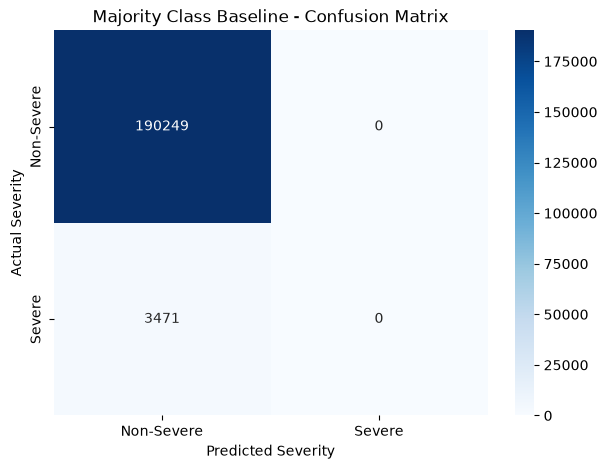

In [41]:

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Severe", "Severe"],
    yticklabels=["Non-Severe", "Severe"]
)

plt.xlabel("Predicted Severity")
plt.ylabel("Actual Severity")
plt.title("Majority Class Baseline - Confusion Matrix")

plt.show()

              precision    recall  f1-score   support

  Non-Severe       0.98      1.00      0.99    190249
      Severe       0.00      0.00      0.00      3471

    accuracy                           0.98    193720
   macro avg       0.49      0.50      0.50    193720
weighted avg       0.96      0.98      0.97    193720



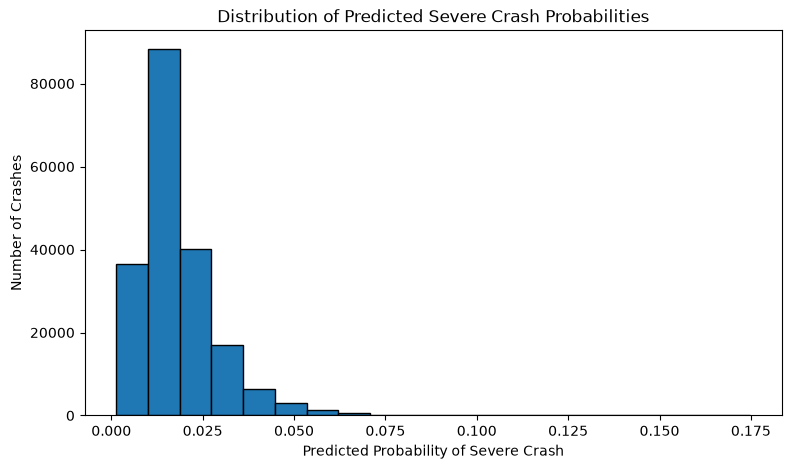

In [42]:
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Non-Severe", "Severe"],
    zero_division=0
))
plt.figure(figsize=(9, 5))

plt.hist(
    severe_probabilities,
    bins=20,
    edgecolor="black"
)

plt.xlabel("Predicted Probability of Severe Crash")
plt.ylabel("Number of Crashes")
plt.title("Distribution of Predicted Severe Crash Probabilities")

plt.show()

#### Models:  Logistic Regression Model 
The logistic regression classifier will classify crashes as severe or non severe compared against the baseline model 

In [43]:


# Numerical features
numerical_features = [
    "posted_speed_limit"
]
categorical_features = [
    "traffic_control_device",
    "device_condition",
    "weather_condition",
    "lighting_condition",
    "trafficway_type",
    "alignment",
    "roadway_surface_cond",
    "road_defect",
    "crash_hour",
    "crash_month",
    "crash_day_of_week"
]


# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [31]:
# Predict crash severity
y_pred = logistic_model.predict(X_test)

# Predict probability of each class
y_prob = logistic_model.predict_proba(X_test)

# Extract probability of a severe crash (class 1)
severe_probabilities = y_prob[:, 1]

print("First 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 severe crash probabilities:")
print(severe_probabilities[:10])

First 10 predictions:
[0 0 0 0 0 0 0 0 0 0]

First 10 severe crash probabilities:
[0.00729008 0.01015249 0.02369725 0.01674645 0.00704978 0.01272405
 0.01847194 0.01381958 0.00408334 0.01380837]


In [44]:
#Evaluate Model
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(y_test, severe_probabilities)

pr_auc = average_precision_score(y_test, severe_probabilities)

brier = brier_score_loss(y_test, severe_probabilities)

print("LOGISTIC REGRESSION RESULTS")
print("--------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"PR-AUC:    {pr_auc:.4f}")
print(f"Brier Score: {brier:.4f}")

LOGISTIC REGRESSION RESULTS
--------------------------------
Accuracy:  0.9821
Precision: 0.0000
Recall:    0.0000
F1 Score:  0.0000
ROC-AUC:   0.6436
PR-AUC:    0.0313
Brier Score: 0.0175


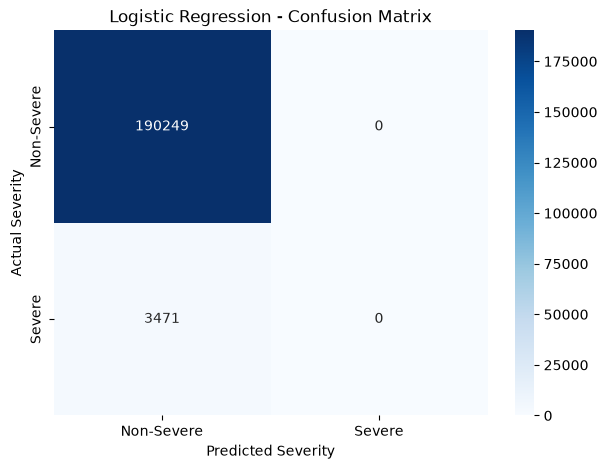

In [45]:
#Confusion Matrix for LRM
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Severe", "Severe"],
    yticklabels=["Non-Severe", "Severe"]
)

plt.xlabel("Predicted Severity")
plt.ylabel("Actual Severity")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()

              precision    recall  f1-score   support

  Non-Severe       0.98      1.00      0.99    190249
      Severe       0.00      0.00      0.00      3471

    accuracy                           0.98    193720
   macro avg       0.49      0.50      0.50    193720
weighted avg       0.96      0.98      0.97    193720



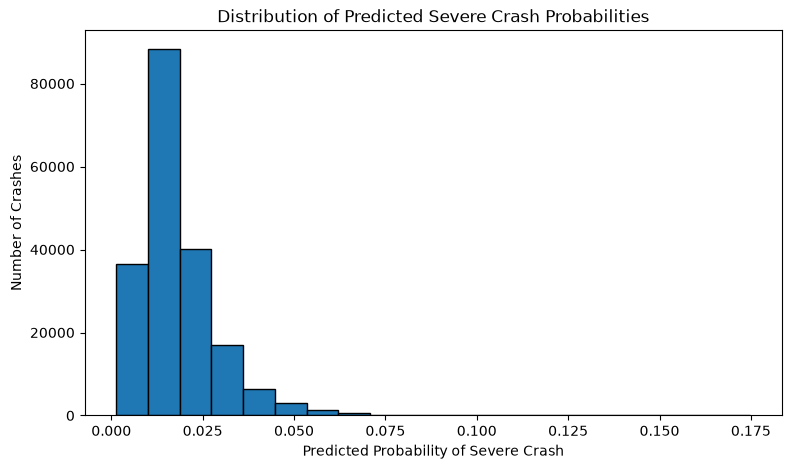

In [46]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-Severe", "Severe"],
    zero_division=0
))
plt.figure(figsize=(9, 5))

plt.hist(
    severe_probabilities,
    bins=20,
    edgecolor="black"
)

plt.xlabel("Predicted Probability of Severe Crash")
plt.ylabel("Number of Crashes")
plt.title("Distribution of Predicted Severe Crash Probabilities")

plt.show()

#### Results


In [47]:
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC",
        "Brier Score"
    ],
    "Majority Class": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1,
        baseline_roc_auc,
        baseline_pr_auc,
        baseline_brier
    ],
    "Logistic Regression": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        pr_auc,
        brier
    ]
})

print(results)

        Metric  Majority Class  Logistic Regression
0     Accuracy        0.982082             0.982082
1    Precision        0.000000             0.000000
2       Recall        0.000000             0.000000
3     F1 Score        0.000000             0.000000
4      ROC-AUC        0.500000             0.643612
5       PR-AUC        0.017918             0.031258
6  Brier Score        0.017918             0.017512


In [48]:
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC",
        "Brier Score"
    ],

    "Majority Class Baseline": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1,
        baseline_roc_auc,
        baseline_pr_auc,
        baseline_brier
    ],

    "Logistic Regression": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        pr_auc,
        brier
    ]
})

print(results.round(4))

        Metric  Majority Class Baseline  Logistic Regression
0     Accuracy                   0.9821               0.9821
1    Precision                   0.0000               0.0000
2       Recall                   0.0000               0.0000
3     F1 Score                   0.0000               0.0000
4      ROC-AUC                   0.5000               0.6436
5       PR-AUC                   0.0179               0.0313
6  Brier Score                   0.0179               0.0175
